# Week 5 Tasks

Each task has a short description followed by its code.

**Setup:** Tasks 2–4 use [Gradio](https://www.gradio.app/) for the frontends — the apps open right inside the notebook. Run the cell below once to install it.

In [1]:
%pip install gradio

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
INFO: pip is looking at multiple versions of httpcore2 to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of httpcore2 to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta

## Task 1 — Titanic: EDA, Feature Engineering & Visualization

Perform complete exploratory data analysis, feature engineering, and data visualization on the Titanic dataset to identify survival patterns and prepare the data for machine learning.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

print("Shape:", titanic.shape)
titanic.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Exploring the data

In [3]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
# Missing values in each column
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Survival patterns

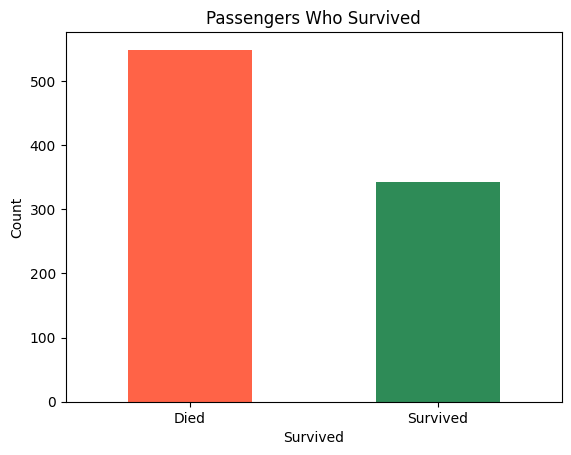

Survival rate: 38.4 %


In [ ]:
titanic["Survived"].value_counts().plot(kind="bar", color=["tomato", "seagreen"])
plt.title("Passengers Who Survived")
plt.xticks([0, 1], ["Died", "Survived"], rotation=0)
plt.ylabel("Count")
plt.show()

print("Survival rate:", round(titanic["Survived"].mean() * 100, 1), "%")

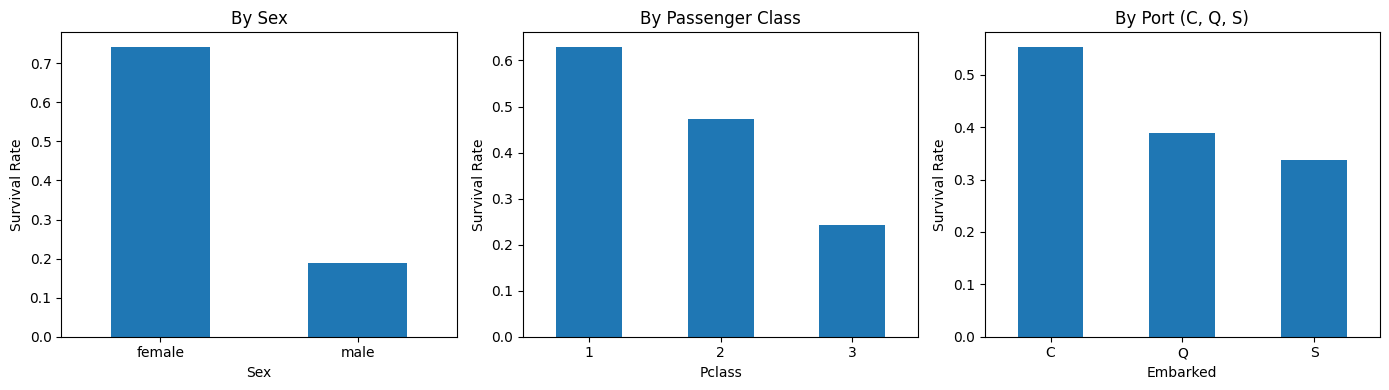

In [7]:
# Survival rate by sex, class and port
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

titanic.groupby("Sex")["Survived"].mean().plot(kind="bar", ax=axes[0], title="By Sex")
titanic.groupby("Pclass")["Survived"].mean().plot(kind="bar", ax=axes[1], title="By Passenger Class")
titanic.groupby("Embarked")["Survived"].mean().plot(kind="bar", ax=axes[2], title="By Port (C, Q, S)")

for ax in axes:
    ax.set_ylabel("Survival Rate")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

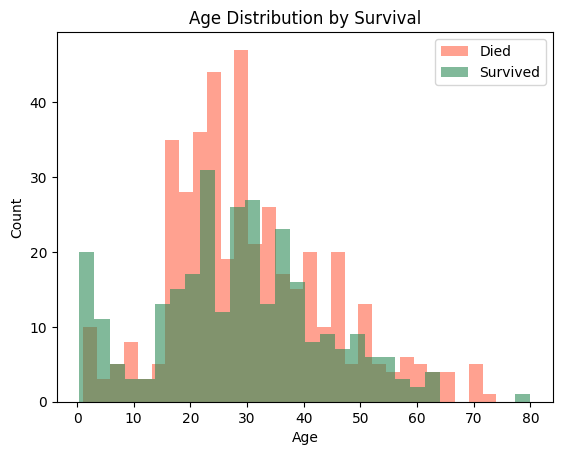

In [8]:
# Age distribution of survivors vs non-survivors
survived = titanic[titanic["Survived"] == 1]["Age"].dropna()
died = titanic[titanic["Survived"] == 0]["Age"].dropna()

plt.hist(died, bins=30, alpha=0.6, label="Died", color="tomato")
plt.hist(survived, bins=30, alpha=0.6, label="Survived", color="seagreen")
plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend()
plt.show()

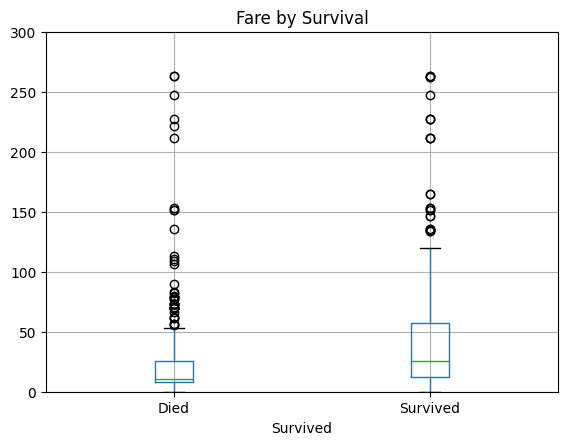

In [9]:
# Fare paid vs survival
titanic.boxplot(column="Fare", by="Survived")
plt.title("Fare by Survival")
plt.suptitle("")
plt.xticks([1, 2], ["Died", "Survived"])
plt.ylim(0, 300)
plt.show()

### Feature engineering

- Fill missing `Age` with the median and `Embarked` with the most common port
- `FamilySize` = siblings/spouses + parents/children + the passenger
- `IsAlone` = travelling with no family
- `Title` extracted from the name (Mr, Mrs, Miss, Master, Rare)
- Convert text columns to numbers and drop columns that are not useful for ML

In [10]:
data = titanic.copy()

# Fill missing values
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

# New features
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.", expand=False)
data["Title"] = data["Title"].replace(["Mlle", "Ms"], "Miss").replace("Mme", "Mrs")
title_counts = data["Title"].value_counts()
data["Title"] = data["Title"].replace(title_counts[title_counts < 10].index, "Rare")

data["Title"].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

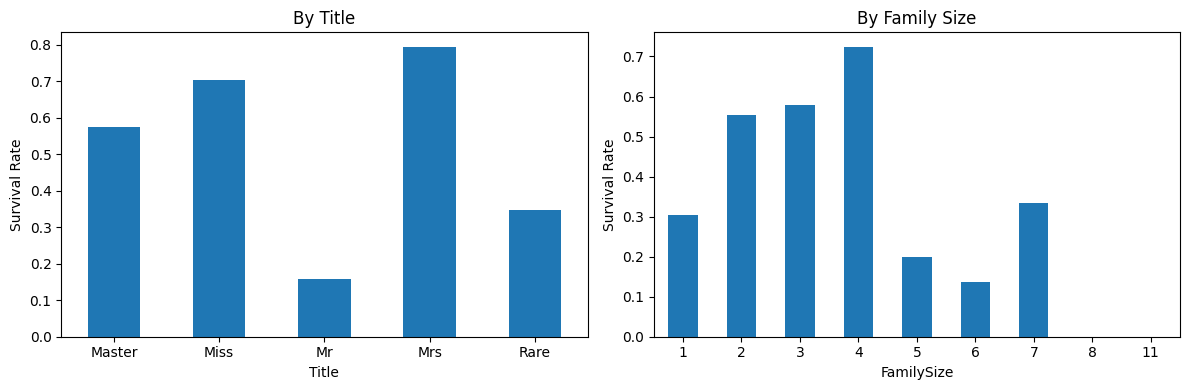

In [11]:
# Survival rate by the new features
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data.groupby("Title")["Survived"].mean().plot(kind="bar", ax=axes[0], title="By Title")
data.groupby("FamilySize")["Survived"].mean().plot(kind="bar", ax=axes[1], title="By Family Size")

for ax in axes:
    ax.set_ylabel("Survival Rate")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [12]:
# Convert text columns to numbers
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
data["Embarked"] = data["Embarked"].map({"S": 0, "C": 1, "Q": 2})
data["Title"] = data["Title"].map({"Mr": 0, "Miss": 1, "Mrs": 2, "Master": 3, "Rare": 4})

# Drop columns that are not useful for machine learning
data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

print("Missing values left:", data.isnull().sum().sum())
data.head()

Missing values left: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
0,0,3,0,22.0,1,0,7.2500,0,2,0,0
1,1,1,1,38.0,1,0,71.2833,1,2,0,2
2,1,3,1,26.0,0,0,7.9250,0,1,1,1
3,1,1,1,35.0,1,0,53.1000,0,2,0,2
4,0,3,0,35.0,0,0,8.0500,0,1,1,0


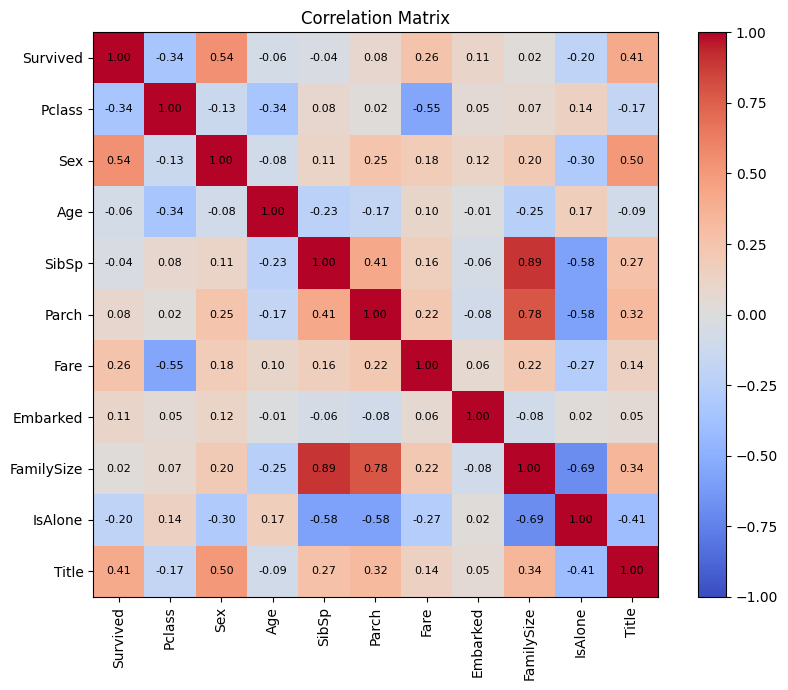

In [13]:
# Correlation between features
corr = data.corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [14]:
# Data ready for machine learning
X = data.drop(columns=["Survived"])
y = data["Survived"]

print("Features:", list(X.columns))
print("X shape:", X.shape, " y shape:", y.shape)

Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'Title']
X shape: (891, 10)  y shape: (891,)


**Key findings**

- Women survived far more often than men (~74% vs ~19%).
- 1st class passengers had the best survival rate, 3rd class the worst.
- Children (title *Master* / young age) survived more often than adult men.
- Passengers who paid higher fares were more likely to survive.
- Travelling alone or in a very large family lowered the chance of survival.

## Task 2 — ML Model with a Frontend

Train a machine learning model on a suitable dataset and develop a user-friendly frontend to input data, generate predictions, and test the model's performance.

We use the cleaned Titanic data from Task 1 to predict whether a passenger survived. *(Run Task 1 first.)*

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Features a user can easily enter in the app
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "FamilySize", "IsAlone"]

X_train, X_test, y_train, y_test = train_test_split(
    data[features], data["Survived"], test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, predictions) * 100, 1), "%")
print(classification_report(y_test, predictions, target_names=["Died", "Survived"]))

Test accuracy: 79.3 %
              precision    recall  f1-score   support

        Died       0.79      0.89      0.83       105
    Survived       0.80      0.66      0.73        74

    accuracy                           0.79       179
   macro avg       0.80      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179



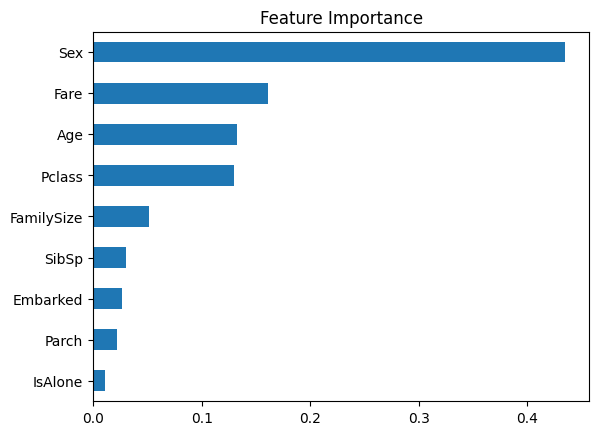

In [16]:
# Which features matter most?
importance = pd.Series(model.feature_importances_, index=features).sort_values()
importance.plot(kind="barh")
plt.title("Feature Importance")
plt.show()

In [17]:
import gradio as gr

ports = {"Southampton": 0, "Cherbourg": 1, "Queenstown": 2}


def predict_survival(pclass, sex, age, sibsp, parch, fare, embarked):
    family_size = sibsp + parch + 1
    passenger = pd.DataFrame([{
        "Pclass": pclass,
        "Sex": 1 if sex == "Female" else 0,
        "Age": age,
        "SibSp": sibsp,
        "Parch": parch,
        "Fare": fare,
        "Embarked": ports[embarked],
        "FamilySize": family_size,
        "IsAlone": 1 if family_size == 1 else 0,
    }])
    chance = model.predict_proba(passenger)[0][1]
    if chance >= 0.5:
        return f"Survived  ({chance:.0%} chance of survival)"
    return f"Did not survive  ({chance:.0%} chance of survival)"


def test_model():
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    report = classification_report(y_test, predictions, target_names=["Died", "Survived"])
    return f"Accuracy on {len(X_test)} test passengers: {accuracy:.1%}\n\n{report}"


with gr.Blocks(title="Titanic Survival Predictor") as titanic_app:
    gr.Markdown("# Titanic Survival Predictor")

    with gr.Tab("Predict"):
        pclass = gr.Radio([1, 2, 3], value=3, label="Passenger Class")
        sex = gr.Radio(["Male", "Female"], value="Male", label="Sex")
        age = gr.Slider(0, 80, value=30, step=1, label="Age")
        sibsp = gr.Slider(0, 8, value=0, step=1, label="Siblings / Spouses aboard")
        parch = gr.Slider(0, 6, value=0, step=1, label="Parents / Children aboard")
        fare = gr.Slider(0, 520, value=30, label="Fare")
        embarked = gr.Dropdown(list(ports), value="Southampton", label="Port of Embarkation")
        predict_button = gr.Button("Predict", variant="primary")
        result = gr.Textbox(label="Prediction")
        predict_button.click(predict_survival, [pclass, sex, age, sibsp, parch, fare, embarked], result)

    with gr.Tab("Test Model"):
        test_button = gr.Button("Run on test set", variant="primary")
        report_box = gr.Textbox(label="Model Performance", lines=10)
        test_button.click(test_model, None, report_box)

titanic_app.launch()

c:\Users\abdul\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Task 3 — 2D CNN Image Classifier with a Frontend

Develop a 2D CNN image classification model and build a user-friendly frontend to upload images and display the predicted class.

We use the **Fashion-MNIST** dataset: 70,000 small grayscale images of 10 clothing types.

In [18]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

(train_images, train_labels), (test_images, test_labels) = keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Scale pixels to 0-1 and add a channel dimension: (28, 28) -> (28, 28, 1)
train_images = train_images.reshape(-1, 28, 28, 1) / 255.0
test_images = test_images.reshape(-1, 28, 28, 1) / 255.0

print("Training images:", train_images.shape)
print("Test images:    ", test_images.shape)

Training images: (60000, 28, 28, 1)
Test images:     (10000, 28, 28, 1)


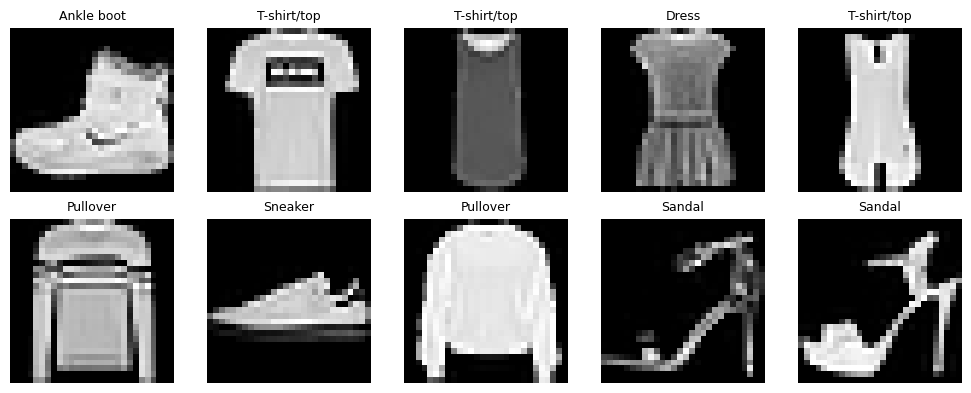

In [19]:
# A few sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images[i].reshape(28, 28), cmap="gray")
    plt.title(class_names[train_labels[i]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [20]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

cnn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
cnn_history = cnn_model.fit(
    train_images, train_labels,
    epochs=5,
    validation_data=(test_images, test_labels),
)

loss, accuracy = cnn_model.evaluate(test_images, test_labels, verbose=0)
print("Test accuracy:", round(accuracy * 100, 1), "%")

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 30s 14ms/step - accuracy: 0.7780 - loss: 0.6221 - val_accuracy: 0.8644 - val_loss: 0.3705
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8864 - loss: 0.3109 - val_accuracy: 0.8909 - val_loss: 0.2996
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - accuracy: 0.9022 - loss: 0.2636 - val_accuracy: 0.8988 - val_loss: 0.2774
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.9152 - loss: 0.2263 - val_accuracy: 0.9022 - val_loss: 0.2720
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - accuracy: 0.9252 - loss: 0.1987 - val_accuracy: 0.9067 - val_loss: 0.2633
Test accuracy: 90.7 %


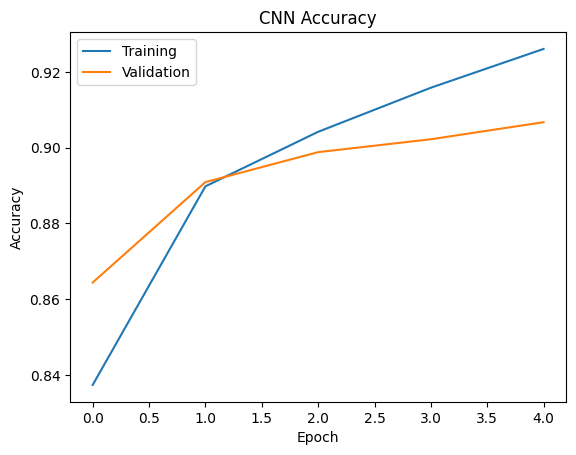

In [22]:
plt.plot(cnn_history.history["accuracy"], label="Training")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [23]:
def classify_image(image):
    gray = tf.image.rgb_to_grayscale(image)
    img = tf.image.resize(gray, (28, 28)).numpy() / 255.0

    # Fashion-MNIST items are light on a dark background,
    # so flip photos that have a light background
    if img.mean() > 0.5:
        img = 1 - img

    probs = cnn_model.predict(img[np.newaxis], verbose=0)[0]
    return {class_names[i]: float(probs[i]) for i in range(10)}


image_app = gr.Interface(
    fn=classify_image,
    inputs=gr.Image(label="Upload a clothing image"),
    outputs=gr.Label(num_top_classes=3, label="Prediction"),
    title="Fashion Image Classifier",
    description="Upload a photo of one of: " + ", ".join(class_names),
)

image_app.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


## Task 4 — 1D CNN Sentiment Analysis with a Frontend

Develop a 1D CNN model for sentiment analysis to classify text as positive or negative and build a frontend to input text and display the predicted sentiment.

We use the **IMDB** dataset: 50,000 movie reviews labelled positive or negative.

In [ ]:
import re

vocab_size = 10000   # keep the 10,000 most common words
max_len = 200        # every review is cut / padded to 200 words

(train_reviews, train_targets), (test_reviews, test_targets) = keras.datasets.imdb.load_data(num_words=vocab_size)
word_index = keras.datasets.imdb.get_word_index()

train_reviews = keras.utils.pad_sequences(train_reviews, maxlen=max_len)
test_reviews = keras.utils.pad_sequences(test_reviews, maxlen=max_len)

print("Training reviews:", train_reviews.shape)
print("Test reviews:    ", test_reviews.shape)

In [ ]:
sentiment_model = keras.Sequential([
    layers.Input(shape=(max_len,)),
    layers.Embedding(vocab_size, 64),
    layers.Conv1D(64, 5, activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

sentiment_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
sentiment_model.summary()

In [ ]:
sentiment_history = sentiment_model.fit(
    train_reviews, train_targets,
    epochs=3,
    batch_size=128,
    validation_data=(test_reviews, test_targets),
)

loss, accuracy = sentiment_model.evaluate(test_reviews, test_targets, verbose=0)
print("Test accuracy:", round(accuracy * 100, 1), "%")

In [ ]:
def encode(text):
    """Turn a review into the same number format the model was trained on."""
    words = re.sub(r"[^a-z0-9' ]", " ", text.lower()).split()
    ids = [1]  # 1 = start of review
    for word in words:
        if word in word_index and word_index[word] + 3 < vocab_size:
            ids.append(word_index[word] + 3)
        else:
            ids.append(2)  # 2 = unknown word
    return keras.utils.pad_sequences([ids], maxlen=max_len)


def predict_sentiment(text):
    score = float(sentiment_model.predict(encode(text), verbose=0)[0][0])
    if score >= 0.5:
        return f"Positive  ({score:.0%} confident)"
    return f"Negative  ({1 - score:.0%} confident)"


sentiment_app = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(lines=4, label="Review", placeholder="Type a movie review..."),
    outputs=gr.Textbox(label="Sentiment"),
    title="Movie Review Sentiment",
    examples=[
        "This movie was fantastic, I loved every minute of it!",
        "Terrible film. Boring plot and awful acting, a waste of time.",
    ],
)

sentiment_app.launch()

## Task 5 — Find the Index of the First Occurrence in a String

Given two strings `needle` and `haystack`, return the index of the first occurrence of `needle` in `haystack`, or `-1` if `needle` is not part of `haystack`.

In [ ]:
haystack = "sadbutsad"
needle = "sad"

index = -1
for i in range(len(haystack) - len(needle) + 1):
    if haystack[i:i + len(needle)] == needle:
        index = i
        break

print("Index:", index)